# Pipeline Incident Risk Scoring, with a Focus on Alberta

**Question:** When an incident happens on a federally regulated pipeline, can we tell from its cause and setting how likely it is to become *significant*, and which factors drive that risk?

Alberta has more reported incidents than any other province in this data (708 of 2,018), so the analysis pays special attention to how the model performs and what it shows there.

**Data:** [Incidents at CER-Regulated Pipelines and Facilities](https://open.canada.ca/data/en/dataset/fd17f08f-f14d-433f-91df-c90a34e1e9a6), Canada Energy Regulator (Open Government Licence – Canada).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix, recall_score, precision_score)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
SEED = 42

## 1. Load and understand the data

In [2]:
df = pd.read_csv("data/pipeline-incidents.csv", encoding="latin-1", low_memory=False)
df["significant"] = (df["Significant"] == "Yes").astype(int)
df["is_alberta"] = df["Province"] == "Alberta"

print(f"{len(df):,} incidents, {df.shape[1] - 2} original columns, years {df['Year'].min()} to {df['Year'].max()}")
print(f"Significant incidents: {df['significant'].mean():.1%} overall, "
      f"{df.loc[df.is_alberta, 'significant'].mean():.1%} in Alberta")
df["Province"].value_counts()

2,018 incidents, 102 original columns, years 2008 to 2026
Significant incidents: 17.8% overall, 14.3% in Alberta


Province
Alberta                  708
British Columbia         574
Ontario                  264
Saskatchewan             179
New Brunswick            105
Manitoba                  85
Quebec                    68
Nova Scotia               25
Northwest Territories     10
Name: count, dtype: int64

The CER flags an incident as **significant** when its consequences are serious, for example a fatality, a serious injury, a fire or explosion, or a large release. About 1 in 6 incidents are significant, so the classes are imbalanced: a model that always predicts "not significant" would be about 82% accurate and completely useless. That is why the evaluation below focuses on **ROC-AUC, PR-AUC and recall** rather than accuracy.

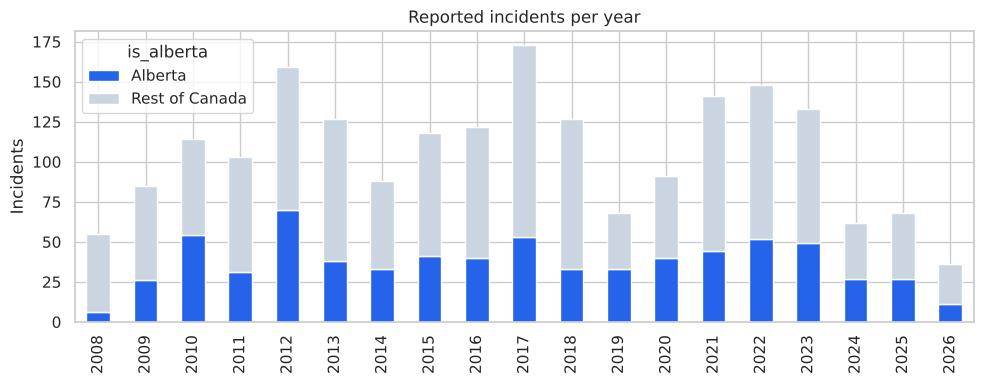

In [3]:
yearly = df.groupby(["Year", "is_alberta"]).size().unstack(fill_value=0).rename(columns={True: "Alberta", False: "Rest of Canada"})
ax = yearly[["Alberta", "Rest of Canada"]].plot(kind="bar", stacked=True, figsize=(10, 4), color=["#2563eb", "#cbd5e1"])
ax.set_title("Reported incidents per year"); ax.set_xlabel(""); ax.set_ylabel("Incidents")
plt.tight_layout(); plt.savefig(FIG / "incidents_per_year.png", dpi=150); plt.show()

Which circumstances are linked to more serious outcomes? The share of incidents that become significant varies a lot by activity and facility type:

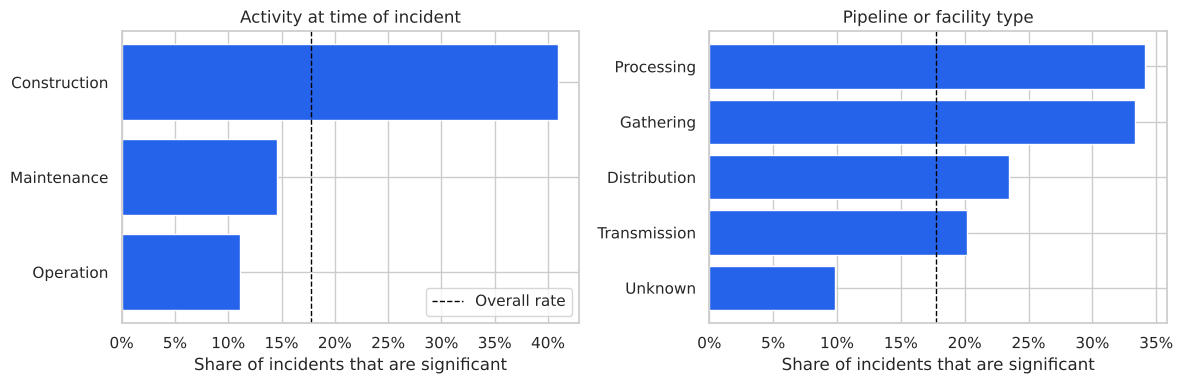

In [4]:
def sig_rate(col):
    s = df[col].fillna("Unknown")
    out = df.assign(k=s).groupby("k")["significant"].agg(rate="mean", n="size")
    return out[out.n >= 30].sort_values("rate")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (col, title) in zip(axes, [("Activity being performed at time of incident", "Activity at time of incident"),
                                   ("Pipeline or Facility Type", "Pipeline or facility type")]):
    r = sig_rate(col)
    ax.barh(r.index, r["rate"], color="#2563eb")
    ax.axvline(df["significant"].mean(), color="black", ls="--", lw=1, label="Overall rate")
    ax.set_title(title); ax.set_xlabel("Share of incidents that are significant")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "significance_by_activity_and_type.png", dpi=150); plt.show()

**Construction** incidents become significant about 41% of the time, nearly four times the rate during normal operation (11%). Processing and gathering facilities also have higher rates than transmission lines. Incidents with an "Unknown" facility type have a low rate, which mostly reflects older records migrated without this field.

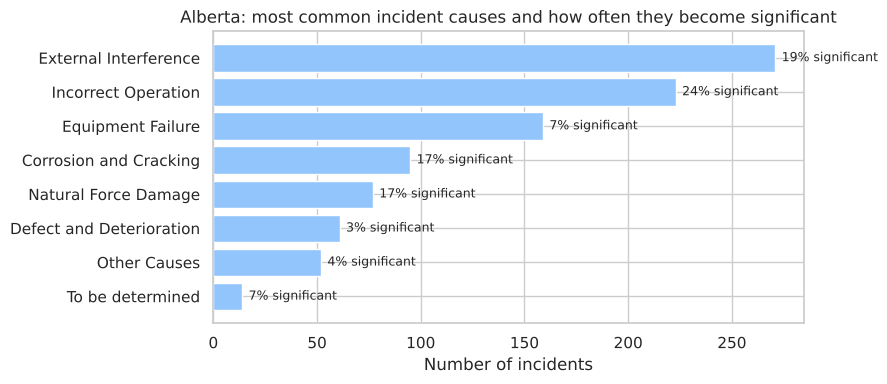

In [5]:
ab = df[df.is_alberta]
what = ab["What happened category"].str.get_dummies(sep=", ")
top = what.sum().sort_values(ascending=False).head(8)
rates = pd.Series({c: ab.loc[what[c] == 1, "significant"].mean() for c in top.index})

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(top.index[::-1], top.values[::-1], color="#93c5fd", label="Incidents")
for i, c in enumerate(top.index[::-1]):
    ax.text(top[c] + 3, i, f"{rates[c]:.0%} significant", va="center", fontsize=9)
ax.set_title("Alberta: most common incident causes and how often they become significant")
ax.set_xlabel("Number of incidents")
plt.tight_layout(); plt.savefig(FIG / "alberta_causes.png", dpi=150); plt.show()

## 2. Build features without leaking the answer

Many columns describe the *outcome* of an incident: the incident type (fire, explosion, injury), volume released, rupture, injuries, evacuations, emergency level and investigation type. These are part of how "significant" is defined, so using them would let the model cheat. They are **excluded**.

The model only uses information about the **cause and setting** of an incident:

- What happened and why it happened (cause categories; an incident can have several)
- Activity at the time (operation, construction, maintenance)
- Pipeline or facility type, land use and province
- How the incident was discovered and whether equipment was involved
- Operating company (companies with fewer than 25 incidents are grouped as "Other")
- Year reported

In [6]:
def multi_hot(col, prefix, min_count=15):
    d = df[col].fillna("Unknown").str.get_dummies(sep=", ")
    d = d.loc[:, d.sum() >= min_count]
    d.columns = [f"{prefix}: {c}" for c in d.columns]
    return d

def one_hot(col, prefix, min_count=15):
    s = df[col].fillna("Unknown")
    counts = s.value_counts()
    s = s.where(s.map(counts) >= min_count, "Other")
    d = pd.get_dummies(s).astype(int)
    d.columns = [f"{prefix}: {c}" for c in d.columns]
    return d

X = pd.concat([
    multi_hot("What happened category", "What"),
    multi_hot("Why it happened category", "Why"),
    one_hot("Activity being performed at time of incident", "Activity"),
    one_hot("Pipeline or Facility Type", "Facility type"),
    one_hot("Land Use", "Land use"),
    one_hot("Province", "Province"),
    one_hot("How the incident was discovered", "Discovered by"),
    one_hot("Pipeline or facility equipment involved", "Equipment involved"),
    one_hot("Company", "Company", min_count=25),
], axis=1)
X["Year"] = df["Year"]
y = df["significant"]
print("Feature matrix:", X.shape)

Feature matrix: (2018, 70)


## 3. Train and compare models

The data is split 80/20 into training and test sets, stratified so both have the same share of significant incidents. Three models are compared with 5-fold cross-validation on the training set only:

- **Logistic regression** (scaled, class-balanced): an interpretable baseline
- **Random forest** (class-balanced): captures interactions between causes and settings
- **Gradient boosting** (class-balanced)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.3, class_weight="balanced")),
    "Random forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=3, class_weight="balanced_subsample",
                                            random_state=SEED, n_jobs=-1),
    "Gradient boosting": HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300,
                                                        class_weight="balanced", random_state=SEED),
}

rows = []
for name, model in models.items():
    cv_auc = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
    model.fit(X_train, y_train)
    p = model.predict_proba(X_test)[:, 1]
    rows.append({"Model": name, "CV ROC-AUC": f"{cv_auc.mean():.3f} ± {cv_auc.std():.3f}",
                 "Test ROC-AUC": round(roc_auc_score(y_test, p), 3),
                 "Test PR-AUC": round(average_precision_score(y_test, p), 3)})
results = pd.DataFrame(rows).set_index("Model")
print(f"PR-AUC of random guessing = share of significant incidents = {y_test.mean():.3f}")
results

PR-AUC of random guessing = share of significant incidents = 0.178


,CV ROC-AUC,Test ROC-AUC,Test PR-AUC
Model,,,
Logistic regression,0.799 ± 0.033,0.785,0.553
Random forest,0.847 ± 0.031,0.838,0.603
Gradient boosting,0.828 ± 0.019,0.817,0.579


The **random forest** performs best in cross-validation and on the test set, so it is used as the risk-scoring model. Its PR-AUC is more than three times what random guessing would achieve.

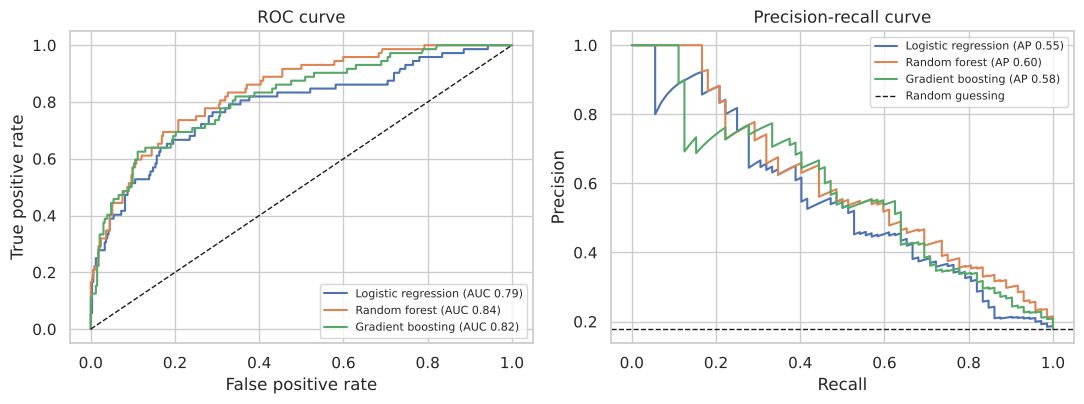

In [8]:
best = models["Random forest"]
p_test = best.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for name, model in models.items():
    p = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.2f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, label=f"{name} (AP {average_precision_score(y_test, p):.2f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label="Random guessing")
axes[1].set(title="Precision-recall curve", xlabel="Recall", ylabel="Precision")
for ax in axes: ax.legend(fontsize=8, loc="lower right" if ax is axes[0] else "upper right")
plt.tight_layout(); plt.savefig(FIG / "roc_pr_curves.png", dpi=150); plt.show()

## 4. Choose a decision threshold

For safety screening, missing a significant incident is worse than reviewing an extra one. Instead of the default 0.5 cut-off, the threshold is chosen **on the training data** (using out-of-fold predictions) as the highest value that still catches at least 75% of significant incidents. The test set is only used to check the result.

Threshold chosen on training data: 0.39
Test recall:    75.0%  (54 of 72 significant incidents flagged)
Test precision: 39.1%


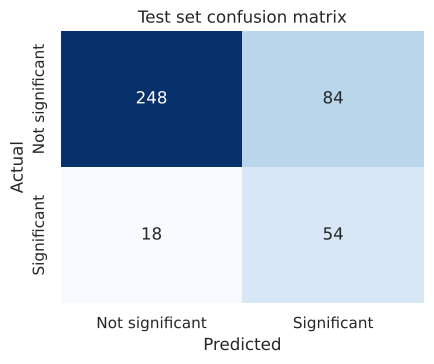

In [9]:
from sklearn.model_selection import cross_val_predict
oof = cross_val_predict(best, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
threshold = thr[np.where(rec[:-1] >= 0.75)[0].max()]

pred = (p_test >= threshold).astype(int)
cm = confusion_matrix(y_test, pred)
print(f"Threshold chosen on training data: {threshold:.2f}")
print(f"Test recall:    {recall_score(y_test, pred):.1%}  ({cm[1,1]} of {cm[1].sum()} significant incidents flagged)")
print(f"Test precision: {precision_score(y_test, pred):.1%}")

plt.figure(figsize=(4.5, 3.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Not significant", "Significant"], yticklabels=["Not significant", "Significant"])
plt.title("Test set confusion matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.savefig(FIG / "confusion_matrix.png", dpi=150); plt.show()

## 5. What drives the risk?

Permutation importance measures how much the test ROC-AUC drops when each feature is shuffled, so it shows which information the model actually relies on.

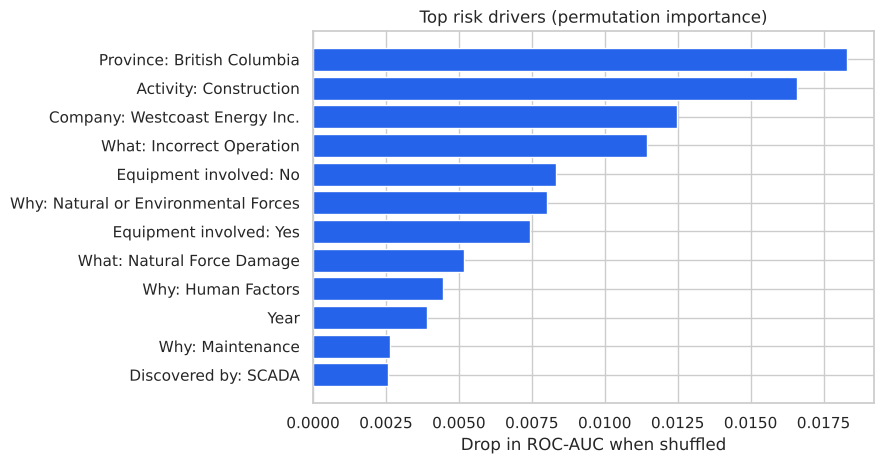

Province: British Columbia              0.0183
Activity: Construction                  0.0166
Company: Westcoast Energy Inc.          0.0125
What: Incorrect Operation               0.0115
Equipment involved: No                  0.0083
Why: Natural or Environmental Forces    0.0080
Equipment involved: Yes                 0.0074
What: Natural Force Damage              0.0052
Why: Human Factors                      0.0045
Year                                    0.0039
Why: Maintenance                        0.0026
Discovered by: SCADA                    0.0026
dtype: float64

In [10]:
imp = permutation_importance(best, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=SEED, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=X.columns).sort_values(ascending=False).head(12)
imp.index = imp.index.str.replace(r",? carrying on business as.*", "", regex=True)

plt.figure(figsize=(9, 4.8))
plt.barh(imp.index[::-1], imp.values[::-1], color="#2563eb")
plt.title("Top risk drivers (permutation importance)"); plt.xlabel("Drop in ROC-AUC when shuffled")
plt.tight_layout(); plt.savefig(FIG / "risk_drivers.png", dpi=150); plt.show()
imp.round(4)

The strongest signals are the **activity** (construction work is the highest-risk setting), **incorrect operation** and **natural force damage** as causes, whether **equipment** was involved, the **province** and the **operator**. These are associations, not proof of cause, but they point to where prevention effort is likely to pay off.

## 6. Risk scoring for Alberta

The model's predicted probability works as a **risk score**. To check whether it is useful in practice, the Alberta incidents in the test set are split into three risk bands.

Alberta test incidents: 132 | ROC-AUC on Alberta only: 0.817


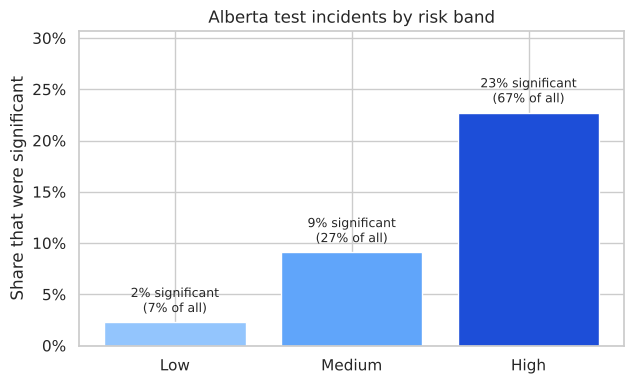

,incidents,significant,significant_rate,share_of_all_significant
band,,,,
Low,44,1,0.023,0.067
Medium,44,4,0.091,0.267
High,44,10,0.227,0.667


In [11]:
ab_mask = df.loc[X_test.index, "is_alberta"].values
ab_scores = pd.DataFrame({"risk_score": p_test[ab_mask], "significant": y_test.values[ab_mask]})
print(f"Alberta test incidents: {len(ab_scores)} | ROC-AUC on Alberta only: {roc_auc_score(ab_scores.significant, ab_scores.risk_score):.3f}")

ab_scores["band"] = pd.qcut(ab_scores["risk_score"].rank(method="first"), 3, labels=["Low", "Medium", "High"])
bands = ab_scores.groupby("band", observed=True).agg(incidents=("significant", "size"),
                                                     significant=("significant", "sum"),
                                                     significant_rate=("significant", "mean"))
bands["share_of_all_significant"] = bands["significant"] / bands["significant"].sum()

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(bands.index.astype(str), bands["significant_rate"], color=["#93c5fd", "#60a5fa", "#1d4ed8"])
for i, (r, s) in enumerate(zip(bands["significant_rate"], bands["share_of_all_significant"])):
    ax.text(i, r + 0.01, f"{r:.0%} significant\n({s:.0%} of all)", ha="center", fontsize=9)
ax.set_title("Alberta test incidents by risk band"); ax.set_ylabel("Share that were significant")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylim(0, bands["significant_rate"].max() * 1.35)
plt.tight_layout(); plt.savefig(FIG / "alberta_risk_bands.png", dpi=150); plt.show()
bands.round(3)

## 7. Conclusions, limitations and next steps

**What the model shows**
- From cause and setting alone, the random forest separates significant from routine incidents well, with a test ROC-AUC of about 0.84 and similar performance on Alberta incidents.
- Construction activity, incorrect operation, natural force damage, equipment involvement, province and operator are the strongest risk drivers.
- On Alberta incidents, the high-risk band concentrates most of the significant incidents, so the score could help prioritize follow-up and inspections.

**Limitations**
- The data only contains incidents, not the pipelines that had none, so this scores **incident severity risk**, not the probability that a given pipeline segment will have an incident.
- Older records were migrated with many unknown fields, and reporting rules have changed over time.
- The test set is small (about 400 incidents, about 130 in Alberta), so results will vary with a different split.

**Next steps**
- Join pipeline asset data (length, age, diameter, material, operating pressure) to model incident likelihood per kilometre, which would allow true segment-level risk scores.
- Validate on the most recent years only (train on earlier years) to test how well the model holds up over time.
- Calibrate the probabilities so the score can be read directly as a likelihood.